# FlashAttention-1 from scratch: tiling, online softmax and recomputation

*Notebook 1 of 6 in the attention series (FA-1 → FA-2 → FA-3 → Flash-Decoding → masks/GQA/block-sparse → Ring Attention).*

**TL;DR.** Standard attention writes an $N\times N$ score matrix to slow GPU memory (HBM, high-bandwidth memory) and reads it back three more times, even though the answer it produces is only $N\times d$. At $N=4096$, $d=64$ that is $16.8$M score elements against $0.26$M output elements, a 64x mismatch. FlashAttention-1 (Dao et al., 2022, [arXiv:2205.14135](https://arxiv.org/abs/2205.14135)) removes the mismatch by computing *exactly the same function* in tiles that fit in fast on-chip memory (SRAM), and by never materialising the $N\times N$ matrix. In this notebook we build the algorithm line by line in PyTorch, check it against a float64 reference, and *count* the memory traffic of both versions. The headline numbers are measured in the last section's table.

**What this notebook is, and is not.** The code is device-agnostic: it runs on CUDA when available and on CPU otherwise (set `FA_DEVICE=cpu` to force CPU), and the printed `device:` line says which. Either way we do not report GPU wall-clock time, because the loops are written for clarity, not speed. What we can do exactly is count how many elements each algorithm moves between slow and fast memory, which is the quantity FlashAttention optimises. Where we quote GPU numbers they come from the papers and are marked *reported*.

**Contents**
1. The memory wall in standard attention
2. Softmax in pieces
3. Online softmax in one pass
4. Tiling Q, K and V
5. Checking exactness and counting traffic
6. Backward pass by recomputation
7. What FlashAttention-1 leaves on the table
8. Closing thoughts

In [1]:
import math, numpy as np, torch, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from fa_kit import *
torch.manual_seed(0); print('device:', DEVICE)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=130)
print("torch", torch.__version__)

device: cpu
torch 2.14.1


## 1. The memory wall in standard attention

We start with the algorithm everyone writes first, because the whole point of FlashAttention is the difference between it and what comes next.

**A tiny example.** Take $N=4$ tokens and head dimension $d=2$. Attention computes, for every query row $q_i$, a weighted average of the value rows, where the weights come from a softmax over $q_i\cdot k_j/\sqrt d$.

In [2]:
q = torch.tensor([[1.,0.],[0.,1.],[1.,1.],[-1.,0.]])
k = torch.tensor([[1.,0.],[0.,1.],[1.,-1.],[0.,0.]])
v = torch.tensor([[1.,2.],[3.,4.],[5.,6.],[7.,8.]])
S = q @ k.T / math.sqrt(2)          # (4,4) scores
P = torch.softmax(S, dim=-1)        # (4,4) each row sums to 1
O = P @ v                           # (4,2)
print("S =\n", S, "\nP =\n", P, "\nrow sums of P:", P.sum(-1), "\nO =\n", O)

S =
 tensor([[ 0.7071,  0.0000,  0.7071,  0.0000],
        [ 0.0000,  0.7071, -0.7071,  0.0000],
        [ 0.7071,  0.7071,  0.0000,  0.0000],
        [-0.7071,  0.0000, -0.7071,  0.0000]]) 
P =
 tensor([[0.3349, 0.1651, 0.3349, 0.1651],
        [0.2212, 0.4486, 0.1091, 0.2212],
        [0.3349, 0.3349, 0.1651, 0.1651],
        [0.1651, 0.3349, 0.1651, 0.3349]]) 
row sums of P: tensor([1., 1., 1., 1.]) 
O =
 tensor([[3.6605, 4.6605],
        [3.6605, 4.6605],
        [3.3210, 4.3210],
        [4.3395, 5.3395]])


**General definition.** For one head with $Q,K,V\in\mathbb R^{N\times d}$,

$$S = \frac{QK^\top}{\sqrt d},\qquad P=\mathrm{softmax}_{\text{row}}(S),\qquad O = PV .$$

**How it is implemented in the standard way.** Three separate GPU kernels, each reading its inputs from HBM and writing its outputs back: (1) a matmul writes $S$; (2) a softmax kernel reads $S$ and writes $P$; (3) a matmul reads $P$ and $V$ and writes $O$. $S$ and $P$ are each $N^2$ elements. Below we write that version and attach an `IOCounter` that records every HBM read and write.

In [3]:
def standard_attention(q, k, v, causal=False, io=None, fl=None):
    """Three 'kernels', each reading from and writing to HBM. Returns O, P."""
    N, d = q.shape
    io = io or IOCounter(); fl = fl or FlopCounter()
    # kernel 1: S = QK^T / sqrt(d)
    io.read("Q", q); io.read("K", k)
    S = (q @ k.T) / math.sqrt(d); fl.mm(N, N, d)
    if causal: S = S.masked_fill(~torch.ones(N, N, dtype=torch.bool).tril(), float("-inf"))
    io.write("S", S)
    # kernel 2: P = softmax(S)
    io.read("S", S)
    P = torch.softmax(S, dim=-1); fl.elt(4 * N * N)       # max, sub, exp, sum/div
    io.write("P", P)
    # kernel 3: O = P V
    io.read("P", P); io.read("V", v)
    O = P @ v; fl.mm(N, d, N)
    io.write("O", O)
    return O, P

io = IOCounter(); O, _ = standard_attention(q, k, v, io=io)
print("tiny example, matches reference:", max_err(O, ref_attention(q, k, v)[0]) < 1e-6)
N, d = 4096, 64
qb, kb, vb = (torch.randn(N, d) for _ in range(3))
io = IOCounter(); fl = FlopCounter(); standard_attention(qb, kb, vb, io=io, fl=fl)
print(f"N={N}, d={d}: HBM elements moved = {io.total/1e6:.1f} M   (S,P alone: {(io.by_tensor()['S']+io.by_tensor()['P'])/1e6:.1f} M)")
print(f"output size N*d = {N*d/1e6:.2f} M elements -> traffic is {io.total/(N*d):.0f}x the output")
check("standard attention matches float64 reference (N=4096)", max_err(standard_attention(qb,kb,vb)[0], ref_attention(qb,kb,vb)[0]) < 1e-3)

tiny example, matches reference: True
N=4096, d=64: HBM elements moved = 68.2 M   (S,P alone: 67.1 M)
output size N*d = 0.26 M elements -> traffic is 260x the output


True

In practice this means the kernel spends its time waiting on memory rather than doing arithmetic. To see why, compare the **arithmetic intensity** (FLOPs per byte moved) with the GPU's *ridge point*, the intensity at which compute and memory take equal time.

standard attention, N=4096, d=64: 4.3 GFLOP over 136 MB -> 31.5 FLOP/byte
A100 ridge point = 208 FLOP/byte -> attention reaches at most 15% of peak (memory-bound)


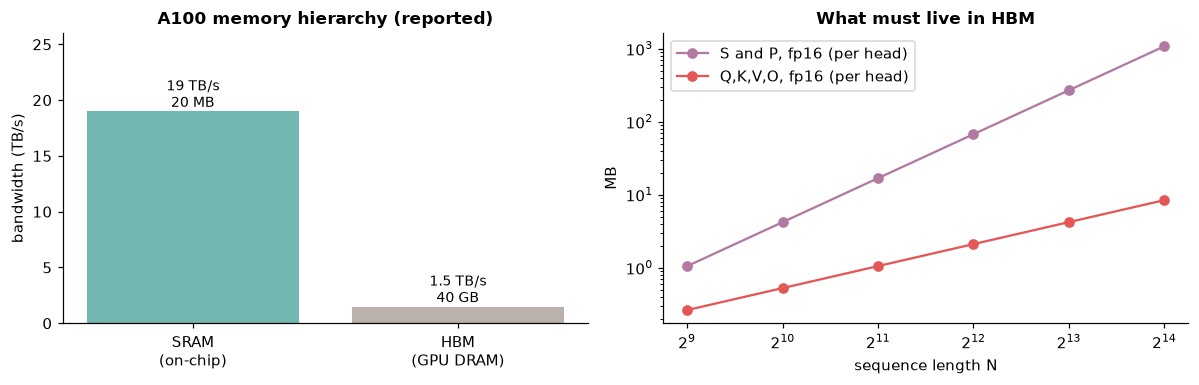

<sub>**Figure.** Left: SRAM is ~13x faster than HBM but ~2000x smaller, so an algorithm that keeps its working set on-chip wins. Right: the S/P intermediates grow as N^2 and overtake the actual inputs/outputs (growing as N) past N = 128 (= 2d); at N = 16k they are about 1.07 GB per head versus 8 MB for Q,K,V,O combined.</sub>

In [4]:
# Recalled A100 specs (reported by NVIDIA / Dao et al., 2022): 312 TFLOP/s fp16 tensor-core, ~1.5-2.0 TB/s HBM, ~19 TB/s SRAM (aggregate), 20 MB SRAM, 40 GB HBM.
PEAK, HBM_BW = 312e12, 1.5e12
bytes_fp16 = io.total * 2
flops = fl.matmul
ai = flops / bytes_fp16
print(f"standard attention, N={N}, d={d}: {flops/1e9:.1f} GFLOP over {bytes_fp16/1e6:.0f} MB -> {ai:.1f} FLOP/byte")
print(f"A100 ridge point = {PEAK/HBM_BW:.0f} FLOP/byte -> attention reaches at most {ai/(PEAK/HBM_BW)*100:.0f}% of peak (memory-bound)")
check("standard attention is memory-bound on A100 (AI < ridge)", ai < PEAK/HBM_BW)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axs[0]
names = ["SRAM\n(on-chip)", "HBM\n(GPU DRAM)"]; bw = [19, 1.5]; cap = [0.02, 40]
ax.bar([0, 1], bw, color=[COL["sram"], COL["hbm"]]); ax.set_xticks([0, 1]); ax.set_xticklabels(names)
for i in range(2): ax.text(i, bw[i] + .4, f"{bw[i]} TB/s\n{['20 MB','40 GB'][i]}", ha="center", fontsize=9)
ax.set_ylim(0, 26); ax.set_ylabel("bandwidth (TB/s)"); ax.set_title("A100 memory hierarchy (reported)")
ax = axs[1]
Ns = np.array([512, 1024, 2048, 4096, 8192, 16384])
ax.plot(Ns, 2*Ns**2*2*1e-6, "o-", color=COL["s"], label="S and P, fp16 (per head)")
ax.plot(Ns, 4*Ns*d*2*1e-6, "o-", color=COL["o"], label="Q,K,V,O, fp16 (per head)")
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("sequence length N"); ax.set_ylabel("MB"); ax.legend(); ax.set_title("What must live in HBM")
plt.tight_layout(); plt.show()
caption("Left: SRAM is ~13x faster than HBM but ~2000x smaller, so an algorithm that keeps its working set on-chip wins. Right: the S/P intermediates grow as N^2 and overtake the actual inputs/outputs (growing as N) past N = 128 (= 2d); at N = 16k they are about 1.07 GB per head versus 8 MB for Q,K,V,O combined.")

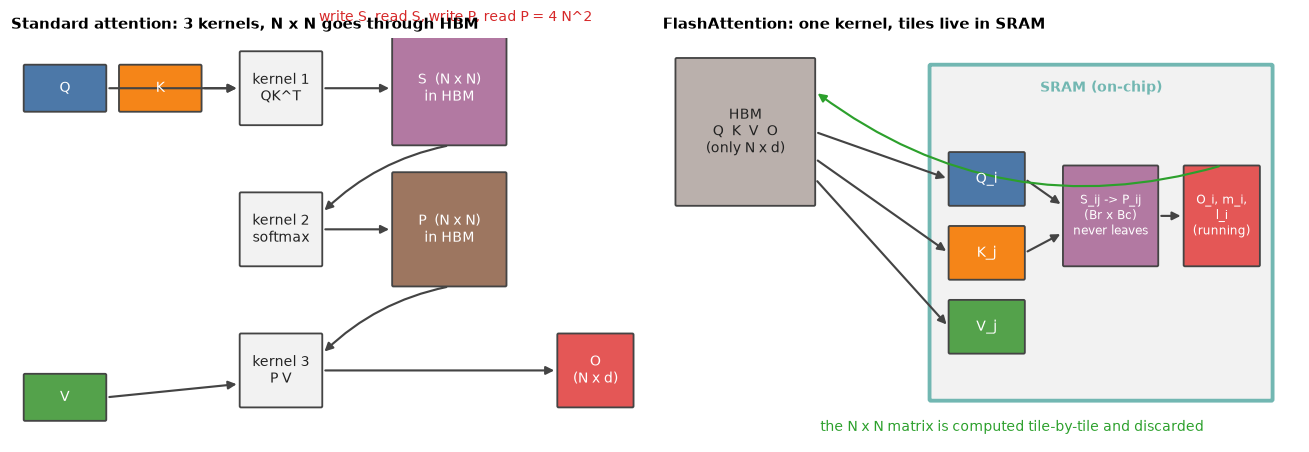

<sub>**Figure.** Left: every arrow into or out of an N x N box is a full pass over N^2 elements. Right: the same two matmuls and the softmax happen inside one kernel on a Br x Bc tile; only Q, K, V, O cross the HBM boundary. Notice that the right panel has no N x N object anywhere.</sub>

In [5]:
# Dataflow figure: standard attention vs the FlashAttention idea.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axs[0]; ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off"); ax.set_title("Standard attention: 3 kernels, N x N goes through HBM", loc="left", fontsize=10)
box(ax, .2, 4.9, 1.3, .7, "Q", COL["q"], tc="w"); box(ax, 1.7, 4.9, 1.3, .7, "K", COL["k"], tc="w")
box(ax, .2, .3, 1.3, .7, "V", COL["v"], tc="w")
box(ax, 3.6, 4.7, 1.3, 1.1, "kernel 1\nQK^T", COL["soft"]); box(ax, 3.6, 2.6, 1.3, 1.1, "kernel 2\nsoftmax", COL["soft"]); box(ax, 3.6, .5, 1.3, 1.1, "kernel 3\nP V", COL["soft"])
box(ax, 6.0, 4.4, 1.8, 1.7, "S  (N x N)\nin HBM", COL["s"], tc="w"); box(ax, 6.0, 2.3, 1.8, 1.7, "P  (N x N)\nin HBM", COL["p"], tc="w")
box(ax, 8.6, .5, 1.2, 1.1, "O\n(N x d)", COL["o"], tc="w")
arrow(ax, (1.5, 5.25), (3.6, 5.25)); arrow(ax, (3.0, 5.25), (3.6, 5.25)); arrow(ax, (4.9, 5.25), (6.0, 5.25)); arrow(ax, (6.9, 4.4), (4.9, 3.4), rad=.15)
arrow(ax, (4.9, 3.15), (6.0, 3.15)); arrow(ax, (6.9, 2.3), (4.9, 1.3), rad=.15); arrow(ax, (1.5, .65), (3.6, .85)); arrow(ax, (4.9, 1.05), (8.6, 1.05))
ax.text(7.0, 6.25, "write S, read S, write P, read P = 4 N^2", fontsize=9, color=COL["bad"], ha="center")
ax = axs[1]; ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off"); ax.set_title("FlashAttention: one kernel, tiles live in SRAM", loc="left", fontsize=10)
box(ax, .2, 3.5, 2.2, 2.2, "HBM\nQ  K  V  O\n(only N x d)", COL["hbm"])
box(ax, 4.2, .6, 5.4, 5.0, "", COL["soft"], ec=COL["sram"], lw=2.5)
ax.text(6.9, 5.2, "SRAM (on-chip)", ha="center", fontsize=9, color=COL["sram"], weight="bold")
box(ax, 4.5, 3.5, 1.2, .8, "Q_i", COL["q"], tc="w"); box(ax, 4.5, 2.4, 1.2, .8, "K_j", COL["k"], tc="w"); box(ax, 4.5, 1.3, 1.2, .8, "V_j", COL["v"], tc="w")
box(ax, 6.3, 2.6, 1.5, 1.5, "S_ij -> P_ij\n(Br x Bc)\nnever leaves", COL["s"], tc="w", fs=8); box(ax, 8.2, 2.6, 1.2, 1.5, "O_i, m_i,\nl_i\n(running)", COL["o"], tc="w", fs=8)
arrow(ax, (2.4, 4.6), (4.5, 3.9)); arrow(ax, (2.4, 4.2), (4.5, 2.8)); arrow(ax, (2.4, 3.9), (4.5, 1.7)); arrow(ax, (5.7, 3.9), (6.3, 3.5)); arrow(ax, (5.7, 2.8), (6.3, 3.1)); arrow(ax, (7.8, 3.35), (8.2, 3.35)); arrow(ax, (8.8, 4.1), (2.4, 5.2), rad=-.25, color=COL["good"])
ax.text(5.5, 0.15, "the N x N matrix is computed tile-by-tile and discarded", fontsize=9, color=COL["good"], ha="center")
plt.tight_layout(); plt.show()
caption("Left: every arrow into or out of an N x N box is a full pass over N^2 elements. Right: the same two matmuls and the softmax happen inside one kernel on a Br x Bc tile; only Q, K, V, O cross the HBM boundary. Notice that the right panel has no N x N object anywhere.")

The idea is simple to state and hard to execute, because softmax needs a *whole row* of $S$ before it can normalise anything, and a tile only holds a few columns of that row. The next section resolves that.

## 2. Softmax in pieces

**A tiny example.** Take one row of scores $x=[1,2,3,4]$ and split it into two blocks, $A=[1,2]$ and $B=[3,4]$. If we softmax each block alone and concatenate, the result is wrong (each half sums to 1, the full row must sum to 1).

In [6]:
x = torch.tensor([1., 2., 3., 4.])
full = torch.softmax(x, 0)
naive = torch.cat([torch.softmax(x[:2], 0), torch.softmax(x[2:], 0)])
print("full softmax        :", full, " sum =", full.sum().item())
print("per-block, naive    :", naive, " sum =", naive.sum().item())
# The fix: carry two statistics per block, (m, l):  m = max,  l = sum(exp(x - m)).
def stats(b): m = b.max(); return m, torch.exp(b - m).sum()
(mA, lA), (mB, lB) = stats(x[:2]), stats(x[2:])
print(f"block A: m={mA:.0f}, l={lA:.4f}   block B: m={mB:.0f}, l={lB:.4f}")
m = torch.maximum(mA, mB); l = lA*torch.exp(mA-m) + lB*torch.exp(mB-m)
print(f"merged : m={m:.0f}, l={l:.4f}  | direct stats of full row: l={stats(x)[1]:.4f}")
check("merging two (m,l) block statistics reproduces the full-row normaliser", abs(l - stats(x)[1]) < 1e-6)

full softmax        : tensor([0.0321, 0.0871, 0.2369, 0.6439])  sum = 0.9999999403953552
per-block, naive    : tensor([0.2689, 0.7311, 0.2689, 0.7311])  sum = 2.0
block A: m=2, l=1.3679   block B: m=4, l=1.3679
merged : m=4, l=1.5530  | direct stats of full row: l=1.5530


tensor(True)

**General definition.** The numerically safe softmax of a vector $x$ is $\mathrm{softmax}(x)_i = e^{x_i-m}/\ell$ with $m=\max_j x_j$ and $\ell=\sum_j e^{x_j-m}$. Subtracting $m$ matters in finite precision: in fp16 the largest finite value is 65504, and $e^{12}=162754$ already overflows. The pair $(m,\ell)$ of two disjoint blocks merges *associatively*:

$$m=\max(m_A,m_B),\qquad \ell = \ell_A\,e^{m_A-m}+\ell_B\,e^{m_B-m}.$$

Associativity is what lets us process a row in any number of pieces, in sequence (FlashAttention) or in parallel across devices (Flash-Decoding, Ring Attention, notebooks 4 and 6).

**How it is implemented.** Each tile keeps its own $(m,\ell)$ and corrects the older tile's numbers with the factor $e^{m_{\text{old}}-m_{\text{new}}}\le 1$. We also quickly confirm the overflow claim, since it is the reason $m$ exists at all.

In [7]:
big = torch.tensor([12., 11.], dtype=torch.float16)
unsafe = torch.exp(big) / torch.exp(big).sum()
safe = torch.exp(big - big.max()) / torch.exp(big - big.max()).sum()
print("fp16 exp(12) =", torch.exp(big)[0].item(), "| unsafe softmax:", unsafe.tolist(), "| safe:", safe.tolist())
check("unsafe fp16 softmax overflows to nan, safe one does not", unsafe.isnan().any().item() and not safe.isnan().any().item())

fp16 exp(12) = inf | unsafe softmax: [nan, 0.0] | safe: [0.73095703125, 0.268798828125]


True

So far we have only normalised the weights. The output $O_i=\sum_j P_{ij}v_j$ also depends on them, which brings us to the part that makes FlashAttention a single pass.

## 3. Online softmax in one pass

**A tiny example.** Process the row $x=[1,2,3,4]$ with values $v=[10,20,30,40]$ (scalars) in blocks of two. After each block we hold an *unnormalised* output $\tilde o=\sum_j e^{x_j-m}v_j$ together with $(m,\ell)$. When a new block raises the max, we multiply $\tilde o$ and $\ell$ by the same correction $e^{m_{\text{old}}-m_{\text{new}}}$. At the end $o=\tilde o/\ell$.

In [8]:
x = torch.tensor([1., 2., 3., 4.]); vv = torch.tensor([10., 20., 30., 40.])
m, l, o = torch.tensor(-float("inf")), torch.tensor(0.), torch.tensor(0.)
for t in range(2):
    xb, vb_ = x[2*t:2*t+2], vv[2*t:2*t+2]
    m_new = torch.maximum(m, xb.max()); alpha = torch.exp(m - m_new)       # correction for old stats
    p = torch.exp(xb - m_new)
    l = alpha * l + p.sum(); o = alpha * o + (p * vb_).sum(); m = m_new
    print(f"after block {t}: m={m:.0f}  l={l:.4f}  o_tilde={o:.4f}  alpha={alpha:.4f}")
print("final o = o_tilde / l =", (o/l).item(), "| direct:", (torch.softmax(x,0)@vv).item())
check("online softmax-weighted average equals direct (tiny example)", abs((o/l) - torch.softmax(x,0)@vv) < 1e-5)

after block 0: m=2  l=1.3679  o_tilde=23.6788  alpha=0.0000
after block 1: m=4  l=1.5530  o_tilde=54.2410  alpha=0.1353
final o = o_tilde / l = 34.92652893066406 | direct: 34.9265251159668


tensor(True)

**General definition.** With a running state $(m,\ell,\tilde o)$ and a new block of scores $s$ (a row of the tile $S_{ij}$) and values $V_j$:

$$m'=\max(m,\max s),\quad \tilde P=e^{s-m'},\quad \ell'=e^{m-m'}\ell+\textstyle\sum\tilde P,\quad \tilde o'=e^{m-m'}\tilde o+\tilde P V_j .$$

After the last block, $o=\tilde o/\ell$, and we also keep the row statistic $L=m+\log\ell$ (the log-sum-exp), which is all the backward pass needs. **Cost:** a few extra element-wise operations per tile and one rescale of the output rows. **Benefit:** the score matrix never needs to exist in full.

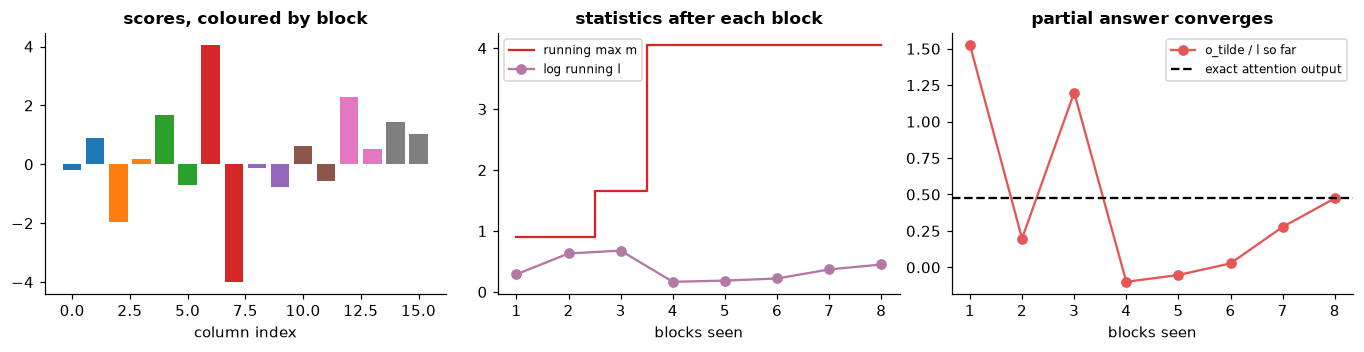

<sub>**Figure.** Left: one row of 16 scores in 8 blocks of 2. Middle: the running max only steps up when a block contains a new maximum, and exactly at those steps the old l is shrunk by e^(m_old - m_new). Right: the partial output after each block is a valid softmax-weighted average of the columns seen so far, and after the last block it lands on the exact answer (dashed).</sub>

True

In [9]:
# Trace the running statistics for a longer row so the mechanism is visible.
g = torch.Generator(device=DEVICE).manual_seed(3)
x = torch.randn(16, generator=g) * 2.5; vv = torch.randn(16, generator=g) * 2
B = 2; T = len(x) // B
ms, ls, os_ = [], [], []
m, l, o = torch.tensor(-float("inf")), torch.tensor(0.), torch.tensor(0.)
for t in range(T):
    xb, vb_ = x[B*t:B*t+B], vv[B*t:B*t+B]
    m_new = torch.maximum(m, xb.max()); a = torch.exp(m - m_new); p = torch.exp(xb - m_new)
    l = a*l + p.sum(); o = a*o + (p*vb_).sum(); m = m_new
    ms.append(m.item()); ls.append(l.item()); os_.append((o/l).item())
true_o = (torch.softmax(x, 0) @ vv).item()
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.3))
axs[0].bar(range(16), x.cpu().numpy(), color=[plt.cm.tab10(i // B % 10) for i in range(16)]); axs[0].set_title("scores, coloured by block"); axs[0].set_xlabel("column index")
axs[1].step(range(1, T+1), ms, where="mid", color=COL["bad"], label="running max m"); axs[1].plot(range(1, T+1), np.log(ls), "o-", color=COL["s"], label="log running l")
axs[1].set_title("statistics after each block"); axs[1].set_xlabel("blocks seen"); axs[1].legend(fontsize=8)
axs[2].plot(range(1, T+1), os_, "o-", color=COL["o"], label="o_tilde / l so far"); axs[2].axhline(true_o, color="k", ls="--", label="exact attention output")
axs[2].set_title("partial answer converges"); axs[2].set_xlabel("blocks seen"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
caption("Left: one row of 16 scores in 8 blocks of 2. Middle: the running max only steps up when a block contains a new maximum, and exactly at those steps the old l is shrunk by e^(m_old - m_new). Right: the partial output after each block is a valid softmax-weighted average of the columns seen so far, and after the last block it lands on the exact answer (dashed).")
check("online trace ends at the exact output", abs(os_[-1] - true_o) < 1e-5)

We now have a row-wise recurrence that needs only two scalars per row plus the partial output. Applying it to many rows and many column blocks at once is what tiling does.

## 4. Tiling Q, K and V

**A tiny example.** Take $N=8$ tokens with row blocks of $B_r=2$ and column blocks of $B_c=2$. The score matrix then has $4\times4=16$ tiles $S_{ij}$. FlashAttention-1 walks them with the **K/V block $j$ as the outer loop** and the Q block $i$ as the inner loop: load $K_j,V_j$ once, then sweep every $Q_i$ against them, merging each result into the running $(O_i,m_i,\ell_i)$ that lives in HBM.

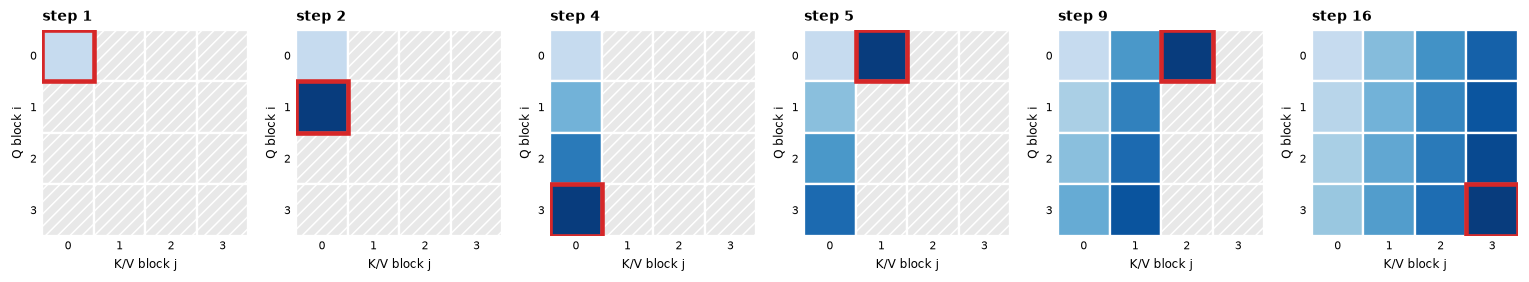

<sub>**Figure.** The red box is the tile being computed. Steps 1-4 fill column j=0 top to bottom (K_0,V_0 stay in SRAM, Q_0..Q_3 stream through); step 5 starts column 1. Notice that O_i is touched once per column, so every O block is read and written 4 times: that repeated traffic is what FlashAttention-2 later removes by swapping the loops.</sub>

In [10]:
nr = nc = 4
order = {}; step = 0
for j in range(nc):                 # FA-1: outer loop over K/V blocks
    for i in range(nr):             # inner loop over Q blocks
        step += 1; order[(i, j)] = step
fig, axs = plt.subplots(1, 6, figsize=(14, 2.9))
for ax, t in zip(axs, [1, 2, 4, 5, 9, 16]):
    vis = {k_: v_ for k_, v_ in order.items() if v_ <= t}
    mask = [[(i, j) in vis for j in range(nc)] for i in range(nr)]
    tile_grid(ax, nr, nc, order=vis, mask=mask, title=f"step {t}", label_order=False)
    ci, cj = [k_ for k_, v_ in order.items() if v_ == t][0]
    ax.add_patch(plt.Rectangle((cj, nr-1-ci), 1, 1, fill=False, ec=COL["bad"], lw=3))
plt.tight_layout(); plt.show()
caption("The red box is the tile being computed. Steps 1-4 fill column j=0 top to bottom (K_0,V_0 stay in SRAM, Q_0..Q_3 stream through); step 5 starts column 1. Notice that O_i is touched once per column, so every O block is read and written 4 times: that repeated traffic is what FlashAttention-2 later removes by swapping the loops.")

**General definition.** Let $T_r=\lceil N/B_r\rceil$ and $T_c=\lceil N/B_c\rceil$. For each tile we compute $S_{ij}=Q_iK_j^\top/\sqrt d$, update the running statistics as in section 3, and rescale the output block. The block sizes are chosen so everything fits in an SRAM budget of $M$ elements: FA-1 uses $B_c=\lceil M/4d\rceil$ and $B_r=\min(B_c,d)$ because it must hold $Q_i,K_j,V_j,O_i$ and the $B_r\times B_c$ tile at once.

**How it is implemented.** Below is the full forward pass. Every `io.read`/`io.write` marks a HBM transfer; every tensor that is a local variable lives in "SRAM". The update line for `O_new` is the paper's $O_i\leftarrow \mathrm{diag}(\ell')^{-1}\big(\mathrm{diag}(\ell)e^{m-m'}O_i+e^{\tilde m-m'}\tilde P V_j\big)$, written without the redundant $\tilde m$.

In [11]:
def fa1_block_sizes(M, d):
    """Paper's choice: Bc = ceil(M/4d), Br = min(Bc, d)."""
    Bc = math.ceil(M / (4 * d)); return min(Bc, d), Bc

def flash1_forward(q, k, v, Br, Bc, causal=False, io=None, fl=None):
    """FlashAttention-1 forward. Outer loop: K/V blocks. Inner loop: Q blocks.
    Returns O (N,d) and L (N,) = row log-sum-exp, the only statistic saved for backward."""
    N, d = q.shape; scale = 1.0 / math.sqrt(d)
    io = io if io is not None else IOCounter(); fl = fl if fl is not None else FlopCounter()
    O = torch.zeros_like(q)                                        # lives in HBM
    l = torch.zeros(N, dtype=q.dtype)                              # running sum, HBM
    m = torch.full((N,), float("-inf"), dtype=q.dtype)             # running max, HBM
    Tr, Tc = math.ceil(N / Br), math.ceil(N / Bc)
    for j in range(Tc):
        js = slice(j * Bc, min((j + 1) * Bc, N))
        Kj, Vj = k[js], v[js]; io.read("K", Kj); io.read("V", Vj)   # load K_j, V_j once
        for i in range(Tr):
            is_ = slice(i * Br, min((i + 1) * Br, N))
            if causal and js.start > is_.stop - 1:                  # tile entirely above the diagonal
                continue
            Qi, Oi, li, mi = q[is_], O[is_], l[is_], m[is_]
            io.read("Q", Qi); io.read("O", Oi); io.read("l", li); io.read("m", mi)
            S = (Qi @ Kj.T) * scale; fl.mm(Qi.shape[0], Kj.shape[0], d); fl.elt(2 * S.numel())
            if causal:                                              # mask only the diagonal tile
                rows = torch.arange(is_.start, is_.stop)[:, None]; cols = torch.arange(js.start, js.stop)[None, :]
                S = S.masked_fill(cols > rows, float("-inf"))
            m_new = torch.maximum(mi, S.max(dim=1).values)
            m_safe = torch.where(torch.isinf(m_new), torch.zeros_like(m_new), m_new)
            P = torch.exp(S - m_safe[:, None]); alpha = torch.exp(mi - m_safe)   # exp(-inf)=0 on first tile
            l_new = alpha * li + P.sum(dim=1); fl.elt(2 * S.numel() + 4 * Qi.shape[0])
            O_new = ((alpha * li)[:, None] * Oi + P @ Vj) / l_new[:, None]; fl.mm(Qi.shape[0], d, Kj.shape[0]); fl.elt(3 * Oi.numel())
            O[is_], l[is_], m[is_] = O_new, l_new, m_new
            io.write("O", O_new); io.write("l", l_new); io.write("m", m_new)
    return O, m + torch.log(l)

# tiny sanity run: N=8, 2x2 tiles
q8, k8, v8 = (torch.randn(8, 4, dtype=torch.float64) for _ in range(3))
O8, L8 = flash1_forward(q8, k8, v8, 2, 2); Or, Lr = ref_attention(q8, k8, v8)
print("N=8 tiles 2x2  max|O - ref| =", max_err(O8, Or), " max|L - lse_ref| =", max_err(L8, Lr))
check("FA-1 forward, N=8, tiles 2x2, matches reference", max_err(O8, Or) < 1e-12 and max_err(L8, Lr) < 1e-12)

N=8 tiles 2x2  max|O - ref| = 3.3306690738754696e-16  max|L - lse_ref| = 4.440892098500626e-16


True

A worked look at what a single query row sees may help build confidence: below we feed the tiles one at a time for row 5 of the $N=8$ example and print the state after each column block.

In [12]:
row = 5; qi = q8[row]; sc = 1/math.sqrt(4)
m_, l_, o_ = torch.tensor(-float("inf"), dtype=torch.float64), torch.tensor(0., dtype=torch.float64), torch.zeros(4, dtype=torch.float64)
print(f"{'col block':>9} {'m':>9} {'l':>9} {'|o|':>9}")
for j in range(4):
    s = (qi @ k8[2*j:2*j+2].T) * sc; mn = torch.maximum(m_, s.max()); a = torch.exp(m_ - mn); p = torch.exp(s - mn)
    l_ = a*l_ + p.sum(); o_ = a*o_ + p @ v8[2*j:2*j+2]; m_ = mn
    print(f"{j:>9} {m_.item():>9.4f} {l_.item():>9.4f} {(o_/l_).norm().item():>9.4f}")
check("row-by-row online update equals the tiled result", max_err(o_/l_, O8[row]) < 1e-12)

col block         m         l       |o|
        0   -0.0548    1.3104    1.6417
        1    0.7391    1.8381    1.5020
        2    1.8050    1.6784    0.8070
        3    1.8050    1.8911    0.7435


True

The loop is exact in arithmetic, so the remaining questions are empirical: does it stay exact for non-trivial sizes, masks and block shapes, and how much traffic does it actually save?

## 5. Checking exactness and counting traffic

FlashAttention is an *exact* algorithm: it reorders the computation but does not approximate it. We test that claim across sequence lengths, head dimensions, block shapes (including ones that do not divide $N$) and causal masking, in float64.

In [13]:
rows = []
for (N_, d_, Br_, Bc_, c_) in [(64,16,8,8,False),(100,16,16,32,False),(130,32,32,64,False),(256,64,64,128,False),(64,16,8,8,True),(100,16,16,32,True),(257,64,64,128,True)]:
    a, b, c = (torch.randn(N_, d_, dtype=torch.float64) for _ in range(3))
    O_, L_ = flash1_forward(a, b, c, Br_, Bc_, causal=c_); Or_, Lr_ = ref_attention(a, b, c, causal=c_)
    e = max(max_err(O_, Or_), max_err(L_, Lr_)); rows.append((N_, d_, Br_, Bc_, c_, e))
    check(f"FA-1 forward exact: N={N_} d={d_} Br={Br_} Bc={Bc_} causal={c_}", e < 1e-11, f"err={e:.1e}")
print(f"worst error over {len(rows)} configs (float64): {max(r[-1] for r in rows):.1e}")
# float32 error vs float64 reference, to show it is as accurate as the standard method
a, b, c = (torch.randn(1024, 64) for _ in range(3))
e_flash = max_err(flash1_forward(a, b, c, 64, 128)[0], ref_attention(a, b, c)[0]); e_std = max_err(standard_attention(a, b, c)[0], ref_attention(a, b, c)[0])
print(f"float32, N=1024: flash error {e_flash:.2e} vs standard error {e_std:.2e} (both against float64)")
check("flash fp32 error is within 3x of standard fp32 error", e_flash < 3 * e_std + 1e-6)

worst error over 7 configs (float64): 1.3e-15
float32, N=1024: flash error 2.90e-07 vs standard error 4.85e-07 (both against float64)


True

Now the traffic. We count HBM element moves for the standard algorithm and for FA-1, using the paper's block-size rule with an SRAM budget of $M=32768$ elements (128 KB at fp32, a plausible per-SM budget). Counting is exact for the loops as written. We first confirm that a closed-form expression matches the counted values, so that we can sweep $N$ and $M$ without running the loops.

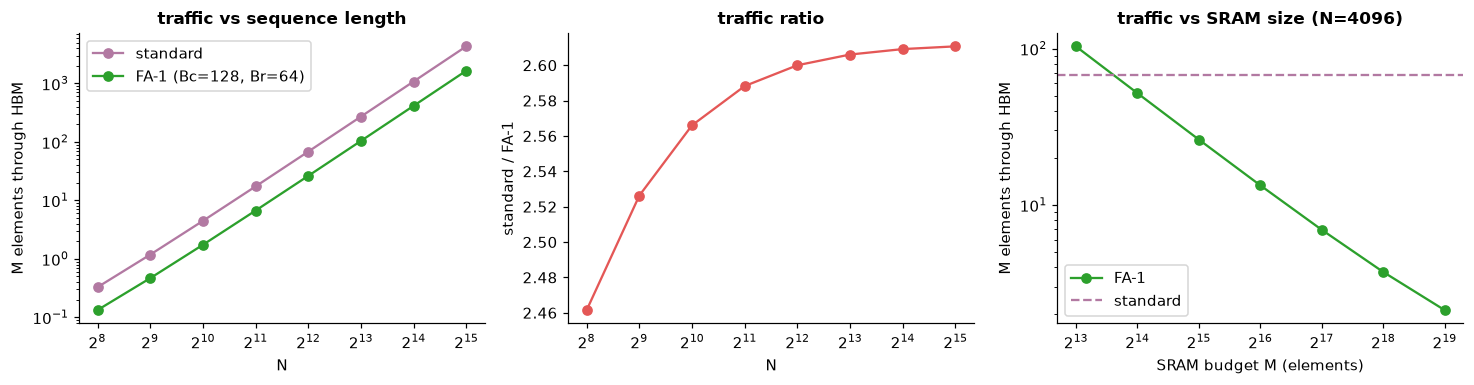

<sub>**Figure.** Left/middle: both curves are quadratic in N, so the advantage is a constant factor set by the block size, not a change of asymptotics; the ratio is flat once N is much larger than Bc. Right: more SRAM means fewer K/V blocks and so proportionally less Q/O re-reading, matching the paper's Theta(N^2 d^2 / M) bound. Notice that at this M the saving is a few-fold, not orders of magnitude.</sub>

True

In [14]:
def io_standard(N, d): return 4*N*N + 4*N*d
def io_flash1(N, d, Br, Bc):
    Tc = math.ceil(N / Bc)
    return 2*N*d + Tc * (3*N*d + 4*N)        # K,V once; per K/V block: read Q,O write O (3Nd) and l,m read/write (4N)

for (N_, d_) in [(256, 32), (512, 64), (1024, 64)]:
    Br_, Bc_ = fa1_block_sizes(32768, d_); x_ = torch.randn(N_, d_)
    io1 = IOCounter(); flash1_forward(x_, x_, x_, Br_, Bc_, io=io1); io0 = IOCounter(); standard_attention(x_, x_, x_, io=io0)
    check(f"closed-form IO == counted IO (N={N_}, d={d_})", io1.total == io_flash1(N_, d_, Br_, Bc_) and io0.total == io_standard(N_, d_), f"flash {io1.total}, std {io0.total}")

M = 32768; d_ = 64; Br_, Bc_ = fa1_block_sizes(M, d_)
fig, axs = plt.subplots(1, 3, figsize=(13.5, 3.6))
Ns = np.array([256, 512, 1024, 2048, 4096, 8192, 16384, 32768])
axs[0].plot(Ns, [io_standard(n, d_)/1e6 for n in Ns], "o-", color=COL["s"], label="standard")
axs[0].plot(Ns, [io_flash1(n, d_, Br_, Bc_)/1e6 for n in Ns], "o-", color=COL["good"], label=f"FA-1 (Bc={Bc_}, Br={Br_})")
axs[0].set_xscale("log", base=2); axs[0].set_yscale("log"); axs[0].set_xlabel("N"); axs[0].set_ylabel("M elements through HBM"); axs[0].legend(); axs[0].set_title("traffic vs sequence length")
axs[1].plot(Ns, [io_standard(n, d_)/io_flash1(n, d_, Br_, Bc_) for n in Ns], "o-", color=COL["o"]); axs[1].set_xscale("log", base=2); axs[1].set_xlabel("N"); axs[1].set_ylabel("standard / FA-1"); axs[1].set_title("traffic ratio")
Ms = np.array([2**p for p in range(13, 20)]); Nf = 4096
axs[2].plot(Ms, [io_flash1(Nf, d_, *fa1_block_sizes(int(mm), d_))/1e6 for mm in Ms], "o-", color=COL["good"], label="FA-1"); axs[2].axhline(io_standard(Nf, d_)/1e6, color=COL["s"], ls="--", label="standard")
axs[2].set_xscale("log", base=2); axs[2].set_yscale("log"); axs[2].set_xlabel("SRAM budget M (elements)"); axs[2].set_ylabel("M elements through HBM"); axs[2].legend(); axs[2].set_title(f"traffic vs SRAM size (N={Nf})")
plt.tight_layout(); plt.show()
caption("Left/middle: both curves are quadratic in N, so the advantage is a constant factor set by the block size, not a change of asymptotics; the ratio is flat once N is much larger than Bc. Right: more SRAM means fewer K/V blocks and so proportionally less Q/O re-reading, matching the paper's Theta(N^2 d^2 / M) bound. Notice that at this M the saving is a few-fold, not orders of magnitude.")
r4096 = io_standard(4096, d_) / io_flash1(4096, d_, Br_, Bc_)
check("FA-1 moves less HBM traffic than standard at N=4096", r4096 > 1.5, f"ratio {r4096:.2f}x")

In [15]:
# Peak *extra* memory beyond inputs/outputs: standard stores S and P, FA-1 stores l, m (or L).
N, d_ = 4096, 64
std_extra = 2 * N * N; fa_extra = 2 * N
print(f"N={N}: standard intermediates {std_extra/1e6:.1f} M elements ({std_extra*2/2**20:.0f} MiB fp16) per head vs FA-1 {fa_extra/1e3:.1f} k elements ({fa_extra*2/2**10:.0f} KiB) -> {std_extra/fa_extra:.0f}x less")
check("memory footprint is linear in N for FA-1 (N^2 -> N)", std_extra // fa_extra == N)

N=4096: standard intermediates 33.6 M elements (64 MiB fp16) per head vs FA-1 8.2 k elements (16 KiB) -> 4096x less


True

We found that forward-pass traffic drops by a constant factor and extra memory drops from quadratic to linear, with identical outputs. The cost shows up in the backward pass, which in a standard implementation needs the $N\times N$ matrix $P$ that we just threw away.

## 6. Backward pass by recomputation

**A tiny example.** Training needs $dQ,dK,dV$. For standard attention they follow from $P$: $dV=P^\top dO$, $dP=dO\,V^\top$, $dS=P\circ(dP-D)$ with $D_i=\sum_j dP_{ij}P_{ij}$, then $dQ=dS\,K/\sqrt d$ and $dK=dS^\top Q/\sqrt d$. FlashAttention does not keep $P$. It keeps $O$ and $L$ (the row log-sum-exp), and rebuilds each tile of $P$ on the fly as $P_{ij}=\exp(S_{ij}-L_i)$. This is *recomputation*: pay one extra matmul to avoid storing $N^2$ numbers.

**A useful identity.** $D_i=\sum_j dP_{ij}P_{ij}=\sum_j (dO_i\cdot v_j)P_{ij}=dO_i\cdot O_i$. So $D$ can be computed from $O$ and $dO$ with an $O(Nd)$ pass, with no need for the full $P$ or $dP$ rows.

In [16]:
# Verify the identity on a random example before relying on it.
a, b, c = (torch.randn(32, 8, dtype=torch.float64) for _ in range(3)); dO = torch.randn(32, 8, dtype=torch.float64)
Pf = torch.softmax(a @ b.T / math.sqrt(8), -1); dPf = dO @ c.T
D_full = (dPf * Pf).sum(1); D_cheap = (dO * (Pf @ c)).sum(1)
print("max |D_full - D_cheap| =", (D_full - D_cheap).abs().max().item())
check("D_i = rowsum(dP*P) equals rowsum(dO*O)", (D_full - D_cheap).abs().max() < 1e-12)

max |D_full - D_cheap| = 4.440892098500626e-16


tensor(True)

**How it is implemented.** The backward pass has the same two-level loop as the forward one (outer over K/V blocks, inner over Q blocks). For each tile it recomputes $S_{ij}$ and $P_{ij}$, accumulates $dV_j$ and $dK_j$ in SRAM across the inner loop, and *adds* into $dQ_i$ in HBM (a read-modify-write, which on a GPU needs atomic adds because different thread blocks update the same $dQ_i$).

In [17]:
def flash1_backward(q, k, v, O, L, dO, Br, Bc, causal=False, io=None, fl=None):
    """FlashAttention-1 backward. Uses only q,k,v,O,L,dO. Never reads a stored P."""
    N, d = q.shape; scale = 1.0 / math.sqrt(d)
    io = io if io is not None else IOCounter(); fl = fl if fl is not None else FlopCounter()
    dq, dk, dv = torch.zeros_like(q), torch.zeros_like(k), torch.zeros_like(v)
    D = (dO * O).sum(dim=1); io.read("O", O); io.read("dO", dO); io.write("D", D)       # preprocessing pass, O(Nd)
    Tr, Tc = math.ceil(N / Br), math.ceil(N / Bc)
    for j in range(Tc):
        js = slice(j * Bc, min((j + 1) * Bc, N)); Kj, Vj = k[js], v[js]; io.read("K", Kj); io.read("V", Vj)
        dKj, dVj = torch.zeros_like(Kj), torch.zeros_like(Vj)                          # SRAM accumulators
        for i in range(Tr):
            is_ = slice(i * Br, min((i + 1) * Br, N))
            if causal and js.start > is_.stop - 1: continue
            Qi, dOi, Li, Di = q[is_], dO[is_], L[is_], D[is_]
            io.read("Q", Qi); io.read("dO", dOi); io.read("L", Li); io.read("D", Di)
            S = (Qi @ Kj.T) * scale; fl.mm(Qi.shape[0], Kj.shape[0], d)                # RECOMPUTE scores
            if causal:
                rows = torch.arange(is_.start, is_.stop)[:, None]; cols = torch.arange(js.start, js.stop)[None, :]
                S = S.masked_fill(cols > rows, float("-inf"))
            P = torch.exp(S - Li[:, None])                                             # RECOMPUTE probabilities from L
            dVj += P.T @ dOi; fl.mm(Kj.shape[0], d, Qi.shape[0])
            dP = dOi @ Vj.T; fl.mm(Qi.shape[0], Kj.shape[0], d)
            dS = P * (dP - Di[:, None]) * scale; fl.elt(3 * P.numel())
            io.read("dQ", Qi); dq[is_] += dS @ Kj; fl.mm(Qi.shape[0], d, Kj.shape[0]); io.write("dQ", Qi)   # HBM read-modify-write
            dKj += dS.T @ Qi; fl.mm(Kj.shape[0], d, Qi.shape[0])
        dk[js], dv[js] = dKj, dVj; io.write("dK", dKj); io.write("dV", dVj)
    return dq, dk, dv

for causal_ in (False, True):
    N_, d_ = 100, 16
    q_, k_, v_ = (torch.randn(N_, d_, dtype=torch.float64, requires_grad=True) for _ in range(3)); dO_ = torch.randn(N_, d_, dtype=torch.float64)
    Oref, _ = ref_attention(q_, k_, v_, causal=causal_); Oref.backward(dO_)
    with torch.no_grad():
        O_, L_ = flash1_forward(q_, k_, v_, 16, 32, causal=causal_); dq_, dk_, dv_ = flash1_backward(q_, k_, v_, O_, L_, dO_, 16, 32, causal=causal_)
    errs = [max_err(dq_, q_.grad), max_err(dk_, k_.grad), max_err(dv_, v_.grad)]
    print(f"causal={causal_}: max|d - autograd| for dQ,dK,dV =", [f"{e:.1e}" for e in errs])
    check(f"FA-1 backward matches autograd (causal={causal_})", max(errs) < 1e-11)

causal=False: max|d - autograd| for dQ,dK,dV = ['5.6e-16', '7.8e-16', '8.9e-16']
causal=True: max|d - autograd| for dQ,dK,dV = ['6.7e-16', '1.1e-15', '1.1e-15']


The gradients agree with autograd to float64 round-off, using only $O$ and $L$ from the forward pass. We now measure what recomputation costs and what it saves.

backward matmul FLOPs: flash 0.67 G  vs standard 0.54 G  -> 1.25x (5 GEMMs instead of 4)
activations saved for backward: standard P (+O) = 1.11 M elements, flash O+L = 0.067 M -> 16.7x less


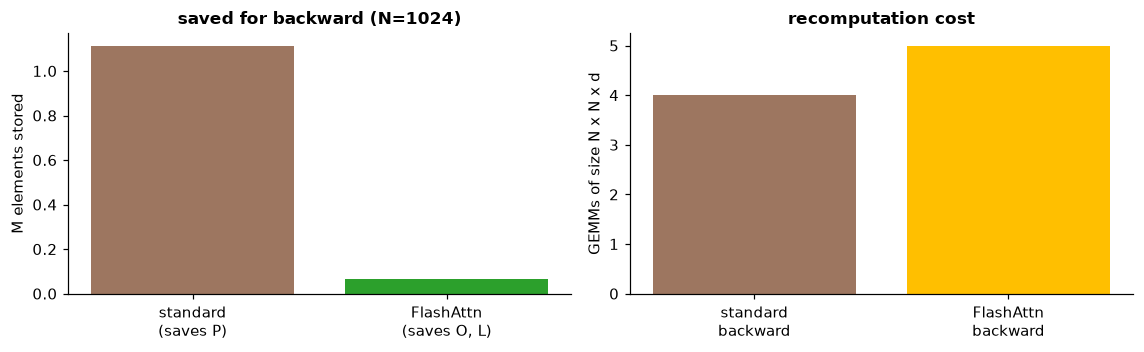

<sub>**Figure.** Left: the storage saved is the whole N x N matrix, about 17x at N=1024 and growing linearly with N. Right: the price is one extra N x N x d matmul in backward (25% more backward matmul FLOPs). We found it is worth paying because the saved FLOPs are cheap and the saved HBM traffic is not.</sub>

In [18]:
N_, d_ = 1024, 64; Br_, Bc_ = fa1_block_sizes(32768, d_)
q_, k_, v_, dO_ = (torch.randn(N_, d_) for _ in range(4))
fl_f, io_f = FlopCounter(), IOCounter(); O_, L_ = flash1_forward(q_, k_, v_, Br_, Bc_, io=io_f, fl=fl_f)
fl_b, io_b = FlopCounter(), IOCounter(); flash1_backward(q_, k_, v_, O_, L_, dO_, Br_, Bc_, io=io_b, fl=fl_b)
std_bwd_matmul = 4 * (2 * N_ * N_ * d_)           # dV, dP, dQ, dK : four GEMMs of 2*N*N*d
print(f"backward matmul FLOPs: flash {fl_b.matmul/1e9:.2f} G  vs standard {std_bwd_matmul/1e9:.2f} G  -> {fl_b.matmul/std_bwd_matmul:.2f}x (5 GEMMs instead of 4)")
saved_std, saved_flash = N_*N_ + N_*d_, N_*d_ + N_
print(f"activations saved for backward: standard P (+O) = {saved_std/1e6:.2f} M elements, flash O+L = {saved_flash/1e6:.3f} M -> {saved_std/saved_flash:.1f}x less")
check("recomputation costs exactly one extra GEMM (5 vs 4)", abs(fl_b.matmul / std_bwd_matmul - 1.25) < 1e-9)
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
axs[0].bar(["standard\n(saves P)", "FlashAttn\n(saves O, L)"], [saved_std/1e6, saved_flash/1e6], color=[COL["p"], COL["good"]]); axs[0].set_ylabel("M elements stored"); axs[0].set_title(f"saved for backward (N={N_})")
axs[1].bar(["standard\nbackward", "FlashAttn\nbackward"], [4, 5], color=[COL["p"], COL["mid"]]); axs[1].set_ylabel("GEMMs of size N x N x d"); axs[1].set_title("recomputation cost")
plt.tight_layout(); plt.show()
caption("Left: the storage saved is the whole N x N matrix, about 17x at N=1024 and growing linearly with N. Right: the price is one extra N x N x d matmul in backward (25% more backward matmul FLOPs). We found it is worth paying because the saved FLOPs are cheap and the saved HBM traffic is not.")

With both directions exact and a quadratic-to-linear memory reduction in hand, the obvious question is what FlashAttention-1 still does inefficiently.

## 7. What FlashAttention-1 leaves on the table

We counted two inefficiencies while building it, and both are visible in the numbers above rather than assumed.

**Output traffic.** Because the outer loop is over K/V blocks, every $O_i$ (and $\ell_i,m_i$) is read and written $T_c$ times. We break the forward traffic down by tensor.

{'K': '1.0%', 'O': '64.0%', 'Q': '32.0%', 'V': '1.0%', 'l': '1.0%', 'm': '1.0%'}
O,l,m share of FA-1 forward HBM traffic: 66.0%
non-matmul element ops = 92.8 M vs matmul FLOPs = 4.29 G  (but a tensor-core matmul FLOP is ~16x cheaper than a scalar one on A100: 312 vs 19.5 TFLOP/s reported)
time-equivalent: non-matmul ~ 1.48 'matmul-GFLOP' vs matmul 4.29 G -> 25.7% of the work-time


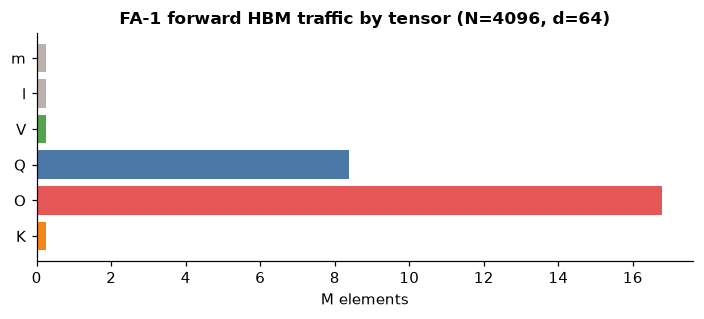

<sub>**Figure.** The O bar dwarfs Q, K and V because the output block is re-read and re-written once per K/V block. Notice that K and V are each loaded exactly once; the inefficiency is entirely in the loop order, not in the amount of input data.</sub>

In [19]:
N_, d_ = 4096, 64; Br_, Bc_ = fa1_block_sizes(32768, d_); x_ = torch.randn(N_, d_)
io_ = IOCounter(); fl_ = FlopCounter(); flash1_forward(x_, x_, x_, Br_, Bc_, io=io_, fl=fl_)
bt = io_.by_tensor(); tot = io_.total
print({k_: f"{v_/tot*100:.1f}%" for k_, v_ in bt.items()})
share_O = (bt["O"] + bt["l"] + bt["m"]) / tot
print(f"O,l,m share of FA-1 forward HBM traffic: {share_O*100:.1f}%")
nonmm = fl_.nonmatmul; mm_ = fl_.matmul
print(f"non-matmul element ops = {nonmm/1e6:.1f} M vs matmul FLOPs = {mm_/1e9:.2f} G  (but a tensor-core matmul FLOP is ~16x cheaper than a scalar one on A100: 312 vs 19.5 TFLOP/s reported)")
eq_cost = nonmm * (312/19.5)
print(f"time-equivalent: non-matmul ~ {eq_cost/1e9:.2f} 'matmul-GFLOP' vs matmul {mm_/1e9:.2f} G -> {eq_cost/(eq_cost+mm_)*100:.1f}% of the work-time")
check("O/l/m traffic is the largest part of FA-1 forward IO (>50%)", share_O > 0.5)
fig, ax = plt.subplots(figsize=(6.5, 3)); ax.barh(list(bt.keys()), [v_/1e6 for v_ in bt.values()], color=[COL.get(k_.lower(), COL["hbm"]) for k_ in bt]); ax.set_xlabel("M elements"); ax.set_title("FA-1 forward HBM traffic by tensor (N=4096, d=64)")
plt.tight_layout(); plt.show()
caption("The O bar dwarfs Q, K and V because the output block is re-read and re-written once per K/V block. Notice that K and V are each loaded exactly once; the inefficiency is entirely in the loop order, not in the amount of input data.")

**Parallelism.** The paper's implementation assigns one thread block per (batch, head) pair, so a batch-1, 16-head call at long sequence length can occupy only 16 of an A100's 108 streaming multiprocessors (the SM count is recalled from the A100 spec; our own code does not measure it). Making sequence length a parallel dimension is the main change in FlashAttention-2.

**Non-matmul work.** The rescaling $\mathrm{diag}(\ell')^{-1}(\cdot)$ is applied on *every* tile, although it is only needed at the end. These element-wise operations run on slower scalar units than the tensor cores, so a small count can matter more than it looks. The next notebook fixes all three issues and re-uses the exact same checks.

## 8. Closing thoughts

Tiling attention to avoid its $N\times N$ intermediates has a longer history than the 2022 paper: Milakov and Gimelshein (2018, [Online normalizer calculation for softmax](https://arxiv.org/abs/1805.02867)) introduced the one-pass $(m,\ell)$ recurrence we used in section 3, and Rabe and Staats (2021, [Self-attention does not need O(n²) memory](https://arxiv.org/abs/2112.05682)) showed the memory reduction before FlashAttention paired it with an explicit model of the HBM/SRAM hierarchy and a fused kernel. The contribution of Dao et al. (2022) was to treat memory traffic as the objective and to make the backward pass recompute rather than store.

**What is open in what we showed.** We measured traffic, not time; the ratio of 2-3x in HBM elements at $M=32768$ is not a speedup prediction, because real kernels are limited by occupancy, tensor-core utilisation and softmax throughput as well. The GPU figures we quoted (bandwidths, SM counts, FLOP rates) are recalled from public specs and papers, not measured here.

**Where the series goes next.** Notebook 2 (FlashAttention-2) swaps the two loops so $O_i$ stays in SRAM, defers the rescale to the end, and splits work across the sequence. Notebooks 4-6 reuse the associative $(m,\ell)$ merge from section 2 in new settings.

Checks run in this notebook:

In [20]:
report()

PASS standard attention matches float64 reference (N=4096)
PASS standard attention is memory-bound on A100 (AI < ridge)
PASS merging two (m,l) block statistics reproduces the full-row normaliser
PASS unsafe fp16 softmax overflows to nan, safe one does not
PASS online softmax-weighted average equals direct (tiny example)
PASS online trace ends at the exact output
PASS FA-1 forward, N=8, tiles 2x2, matches reference
PASS row-by-row online update equals the tiled result
PASS FA-1 forward exact: N=64 d=16 Br=8 Bc=8 causal=False   [err=8.9e-16]
PASS FA-1 forward exact: N=100 d=16 Br=16 Bc=32 causal=False   [err=8.9e-16]
PASS FA-1 forward exact: N=130 d=32 Br=32 Bc=64 causal=False   [err=8.9e-16]
PASS FA-1 forward exact: N=256 d=64 Br=64 Bc=128 causal=False   [err=8.9e-16]
PASS FA-1 forward exact: N=64 d=16 Br=8 Bc=8 causal=True   [err=8.9e-16]
PASS FA-1 forward exact: N=100 d=16 Br=16 Bc=32 causal=True   [err=8.9e-16]
PASS FA-1 forward exact: N=257 d=64 Br=64 Bc=128 causal=True   [err=1.3e-